In [68]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Step 1: Open the file and read the whole dataset

In [69]:
data = pd.read_csv('M1 Forecast_Data_Set.csv')
data

,station,Date,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,...,LDAPS_PPT2,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation,Next_Tmax,Next_Tmin
0,1.0,2013-06-30,28.7,21.4,58.255688,91.116364,28.074101,23.006936,6.818887,69.451805,...,0.000000,0.000000,0.000000,37.6046,126.991,212.3350,2.785000,5992.895996,29.1,21.2
1,2.0,2013-06-30,31.9,21.6,52.263397,90.604721,29.850689,24.035009,5.691890,51.937448,...,0.000000,0.000000,0.000000,37.6046,127.032,44.7624,0.514100,5869.312500,30.5,22.5
2,3.0,2013-06-30,31.6,23.3,48.690479,83.973587,30.091292,24.565633,6.138224,20.573050,...,0.000000,0.000000,0.000000,37.5776,127.058,33.3068,0.266100,5863.555664,31.1,23.9
3,4.0,2013-06-30,32.0,23.4,58.239788,96.483688,29.704629,23.326177,5.650050,65.727144,...,0.000000,0.000000,0.000000,37.6450,127.022,45.7160,2.534800,5856.964844,31.7,24.3
4,5.0,2013-06-30,31.4,21.9,56.174095,90.155128,29.113934,23.486480,5.735004,107.965535,...,0.000000,0.000000,0.000000,37.5507,127.135,35.0380,0.505500,5859.552246,31.2,22.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7747,23.0,2017-08-30,23.3,17.1,26.741310,78.869858,26.352081,18.775678,6.148918,72.058294,...,0.000000,0.000000,0.000000,37.5372,126.891,15.5876,0.155400,4443.313965,28.3,18.1
7748,24.0,2017-08-30,23.3,17.7,24.040634,77.294975,27.010193,18.733519,6.542819,47.241457,...,0.000000,0.000000,0.000000,37.5237,126.909,17.2956,0.222300,4438.373535,28.6,18.8
7749,25.0,2017-08-30,23.2,17.4,22.933014,77.243744,27.939516,18.522965,7.289264,9.090034,...,0.000000,0.000000,0.000000,37.5237,126.970,19.5844,0.271300,4451.345215,27.8,17.4
7750,NaN,NaN,20.0,11.3,19.794666,58.936283,17.624954,14.272646,2.882580,-13.603212,...,0.000000,0.000000,0.000000,37.4562,126.826,12.3700,0.098475,4329.520508,17.4,11.3


In [70]:
data.columns

Index(['station', 'Date', 'Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin',
       'LDAPS_RHmax', 'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS',
       'LDAPS_LH', 'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4',
       'LDAPS_PPT1', 'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4', 'lat', 'lon',
       'DEM', 'Slope', 'Solar radiation', 'Next_Tmax', 'Next_Tmin'],
      dtype='str')

In [71]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7752 entries, 0 to 7751
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   station           7750 non-null   float64
 1   Date              7750 non-null   str    
 2   Present_Tmax      7682 non-null   float64
 3   Present_Tmin      7682 non-null   float64
 4   LDAPS_RHmin       7677 non-null   float64
 5   LDAPS_RHmax       7677 non-null   float64
 6   LDAPS_Tmax_lapse  7677 non-null   float64
 7   LDAPS_Tmin_lapse  7677 non-null   float64
 8   LDAPS_WS          7677 non-null   float64
 9   LDAPS_LH          7677 non-null   float64
 10  LDAPS_CC1         7677 non-null   float64
 11  LDAPS_CC2         7677 non-null   float64
 12  LDAPS_CC3         7677 non-null   float64
 13  LDAPS_CC4         7677 non-null   float64
 14  LDAPS_PPT1        7677 non-null   float64
 15  LDAPS_PPT2        7677 non-null   float64
 16  LDAPS_PPT3        7677 non-null   float64
 17  LDAPS_

## Step 2: Check for any missing variables. If detected, with 2 methods show how you handle missing values. 

In [72]:
data.isnull().sum()

station              2
Date                 2
Present_Tmax        70
Present_Tmin        70
LDAPS_RHmin         75
LDAPS_RHmax         75
LDAPS_Tmax_lapse    75
LDAPS_Tmin_lapse    75
LDAPS_WS            75
LDAPS_LH            75
LDAPS_CC1           75
LDAPS_CC2           75
LDAPS_CC3           75
LDAPS_CC4           75
LDAPS_PPT1          75
LDAPS_PPT2          75
LDAPS_PPT3          75
LDAPS_PPT4          75
lat                  0
lon                  0
DEM                  0
Slope                0
Solar radiation      0
Next_Tmax           27
Next_Tmin           27
dtype: int64

In [73]:
## 1st Method: Dropping the rows with missing values [station, Date, Next_Tmax, Next_Tmin]

data = data.dropna(subset=['station', 'Date', 'Next_Tmax', 'Next_Tmin'])

data.isnull().sum()

station              0
Date                 0
Present_Tmax        60
Present_Tmin        60
LDAPS_RHmin         75
LDAPS_RHmax         75
LDAPS_Tmax_lapse    75
LDAPS_Tmin_lapse    75
LDAPS_WS            75
LDAPS_LH            75
LDAPS_CC1           75
LDAPS_CC2           75
LDAPS_CC3           75
LDAPS_CC4           75
LDAPS_PPT1          75
LDAPS_PPT2          75
LDAPS_PPT3          75
LDAPS_PPT4          75
lat                  0
lon                  0
DEM                  0
Slope                0
Solar radiation      0
Next_Tmax            0
Next_Tmin            0
dtype: int64

In [74]:
## 2nd Method: Filling the missing values with mean of the columns [Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin', 'LDAPS_RHmax', 'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS', 'LDAPS_LH', 'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4', 'LDAPS_PPT1', 'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4']

from sklearn.impute import SimpleImputer

columns_to_impute = ['Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin', 'LDAPS_RHmax', 'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS', 'LDAPS_LH', 'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4', 'LDAPS_PPT1', 'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4']

imputer = SimpleImputer(strategy='mean')

data[columns_to_impute] = imputer.fit_transform(data[columns_to_impute])

data.isnull().sum()

station             0
Date                0
Present_Tmax        0
Present_Tmin        0
LDAPS_RHmin         0
LDAPS_RHmax         0
LDAPS_Tmax_lapse    0
LDAPS_Tmin_lapse    0
LDAPS_WS            0
LDAPS_LH            0
LDAPS_CC1           0
LDAPS_CC2           0
LDAPS_CC3           0
LDAPS_CC4           0
LDAPS_PPT1          0
LDAPS_PPT2          0
LDAPS_PPT3          0
LDAPS_PPT4          0
lat                 0
lon                 0
DEM                 0
Slope               0
Solar radiation     0
Next_Tmax           0
Next_Tmin           0
dtype: int64

## Step 3: Verify the dataset for any duplicated rows. If duplicates are identified, eliminate them.

In [75]:
data.duplicated().sum()

np.int64(0)

In [76]:
data.drop_duplicates(inplace=True)

## Step 4: Preform feature normalization between 0 and 1 if it is needed. Normalization helps to converge machine learning algorithms faster. 

In [77]:
from sklearn.preprocessing import MinMaxScaler

exclude_columns = [
    'station',
    'Date',
    'Next_Tmax',
    'Next_Tmin'
]

columns_to_normalize = [
    col for col in data.select_dtypes(include='number').columns
    if col not in exclude_columns
]

In [78]:
scaler = MinMaxScaler()

data[columns_to_normalize] = scaler.fit_transform(
    data[columns_to_normalize]
)

data.head()

,station,Date,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,...,LDAPS_PPT2,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation,Next_Tmax,Next_Tmin
0,1.0,2013-06-30,0.494318,0.543011,0.488518,0.783659,0.499546,0.569132,0.207447,0.365853,...,0.0,0.0,0.0,0.786017,0.533981,1.000000,0.528870,1.000000,29.1,21.2
1,2.0,2013-06-30,0.676136,0.553763,0.412406,0.771200,0.584480,0.636121,0.148053,0.288703,...,0.0,0.0,0.0,0.786017,0.666667,0.161990,0.081816,0.925703,30.5,22.5
2,3.0,2013-06-30,0.659091,0.645161,0.367024,0.609716,0.595982,0.670697,0.171575,0.150545,...,0.0,0.0,0.0,0.643008,0.750809,0.104702,0.032994,0.922242,31.1,23.9
3,4.0,2013-06-30,0.681818,0.650538,0.488316,0.914366,0.577497,0.589934,0.145848,0.349446,...,0.0,0.0,0.0,1.000000,0.634304,0.166759,0.479615,0.918280,31.7,24.3
4,5.0,2013-06-30,0.647727,0.569892,0.462078,0.760251,0.549257,0.600379,0.150325,0.535505,...,0.0,0.0,0.0,0.500530,1.000000,0.113360,0.080123,0.919835,31.2,22.5


In [79]:
data[columns_to_normalize].describe().loc[['min', 'max']]

,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,LDAPS_CC1,LDAPS_CC2,...,LDAPS_CC4,LDAPS_PPT1,LDAPS_PPT2,LDAPS_PPT3,LDAPS_PPT4,lat,lon,DEM,Slope,Solar radiation
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Step 5: Examine the dataset for categorical variables. If any are found, convert them to numerical variables.

In [80]:
data.dtypes

station             float64
Date                    str
Present_Tmax        float64
Present_Tmin        float64
LDAPS_RHmin         float64
LDAPS_RHmax         float64
LDAPS_Tmax_lapse    float64
LDAPS_Tmin_lapse    float64
LDAPS_WS            float64
LDAPS_LH            float64
LDAPS_CC1           float64
LDAPS_CC2           float64
LDAPS_CC3           float64
LDAPS_CC4           float64
LDAPS_PPT1          float64
LDAPS_PPT2          float64
LDAPS_PPT3          float64
LDAPS_PPT4          float64
lat                 float64
lon                 float64
DEM                 float64
Slope               float64
Solar radiation     float64
Next_Tmax           float64
Next_Tmin           float64
dtype: object

In [81]:
# Convert Date to datetime
data['Date'] = pd.to_datetime(data['Date'])

# Extract numerical date features
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Day'] = data['Date'].dt.day

# Remove original Date column
data.drop(columns=['Date'], inplace=True)

In [82]:
data['station'] = data['station'].astype(str)

# One-hot encode station
data = pd.get_dummies(
    data,
    columns=['station'],
    prefix='station',
    dtype=int
)

In [83]:
data.columns

Index(['Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin', 'LDAPS_RHmax',
       'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS', 'LDAPS_LH',
       'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4', 'LDAPS_PPT1',
       'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4', 'lat', 'lon', 'DEM', 'Slope',
       'Solar radiation', 'Next_Tmax', 'Next_Tmin', 'Year', 'Month', 'Day',
       'station_1.0', 'station_10.0', 'station_11.0', 'station_12.0',
       'station_13.0', 'station_14.0', 'station_15.0', 'station_16.0',
       'station_17.0', 'station_18.0', 'station_19.0', 'station_2.0',
       'station_20.0', 'station_21.0', 'station_22.0', 'station_23.0',
       'station_24.0', 'station_25.0', 'station_3.0', 'station_4.0',
       'station_5.0', 'station_6.0', 'station_7.0', 'station_8.0',
       'station_9.0'],
      dtype='str')

#### The Date variable was stored as a string and was converted into numerical Year, Month, and Day features. The station variable was treated as categorical because its numerical values represent station identifiers rather than continuous quantities. One-hot encoding was used to convert the station categories into numerical variables.

## Step 6: Find correlations between the variables and visualize the correlation matrix using a b) heatmap (1 plot) and c) Scatterplot (minimum 2 plots).

In [84]:
matrix = data.corr()

matrix

,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,LDAPS_CC1,LDAPS_CC2,...,station_23.0,station_24.0,station_25.0,station_3.0,station_4.0,station_5.0,station_6.0,station_7.0,station_8.0,station_9.0
Present_Tmax,1.000000,0.617749,-0.206953,-0.304556,0.568932,0.623175,-0.124903,0.133108,-0.313537,-0.215114,...,0.053862,0.036433,0.048484,-0.001065,0.025737,-0.000107,0.028962,-0.008202,0.001355,0.012275
Present_Tmin,0.617749,1.000000,0.120531,-0.018345,0.462196,0.762384,-0.038305,-0.012673,0.083284,0.088942,...,0.081652,0.088390,0.074150,0.018349,0.032445,-0.014890,0.069181,0.044683,0.044896,-0.009156
LDAPS_RHmin,-0.206953,0.120531,1.000000,0.578708,-0.568968,0.086273,0.291812,-0.072808,0.613201,0.744980,...,0.026684,-0.019864,-0.073551,-0.079340,0.104505,0.035698,-0.042108,0.101288,-0.008415,0.070249
LDAPS_RHmax,-0.304556,-0.018345,0.578708,1.000000,-0.377209,-0.117417,0.132796,0.237706,0.436276,0.391003,...,-0.028959,-0.085840,-0.141861,-0.095352,0.201143,0.101963,-0.073785,0.099798,-0.022913,0.090332
LDAPS_Tmax_lapse,0.568932,0.462196,-0.568968,-0.377209,1.000000,0.653320,-0.316285,0.044499,-0.440665,-0.526132,...,-0.016940,0.022140,0.074653,0.080127,-0.049742,-0.010833,0.034583,-0.073873,0.005206,-0.058789
LDAPS_Tmin_lapse,0.623175,0.762384,0.086273,-0.117417,0.653320,1.000000,-0.133353,-0.138403,0.008993,0.045908,...,0.046235,0.060537,0.076935,0.043903,-0.082849,-0.023463,0.036465,-0.005515,0.015347,-0.033095
LDAPS_WS,-0.124903,-0.038305,0.291812,0.132796,-0.316285,-0.133353,1.000000,0.003230,0.287090,0.258623,...,-0.012306,0.007247,0.018593,-0.011259,0.004521,-0.045780,-0.010468,-0.060064,-0.000839,-0.014338
LDAPS_LH,0.133108,-0.012673,-0.072808,0.237706,0.044499,-0.138403,0.003230,1.000000,-0.148572,-0.265604,...,0.091817,-0.074017,-0.208793,-0.230208,0.150746,0.254554,-0.042425,0.286520,-0.069782,0.129174
LDAPS_CC1,-0.313537,0.083284,0.613201,0.436276,-0.440665,0.008993,0.287090,-0.148572,1.000000,0.779291,...,0.004973,0.005811,0.006114,0.005758,-0.021060,-0.001033,0.004807,0.004928,0.005221,0.000800
LDAPS_CC2,-0.215114,0.088942,0.744980,0.391003,-0.526132,0.045908,0.258623,-0.265604,0.779291,1.000000,...,0.003372,0.004674,0.003890,0.005415,-0.015046,0.001053,0.003609,0.004961,0.003617,0.004481


In [85]:
# Exclude station dummy variables only for easier visualization
heatmap_columns = [
    col for col in data.columns
    if not col.startswith('station_')
]

corr_heatmap = data[heatmap_columns].corr()

plt.figure(figsize=(16, 12))

sns.heatmp(
    corr_heatmap,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix Heatmap')
plt.show()

AttributeError: module 'seaborn' has no attribute 'sns.heatmp'

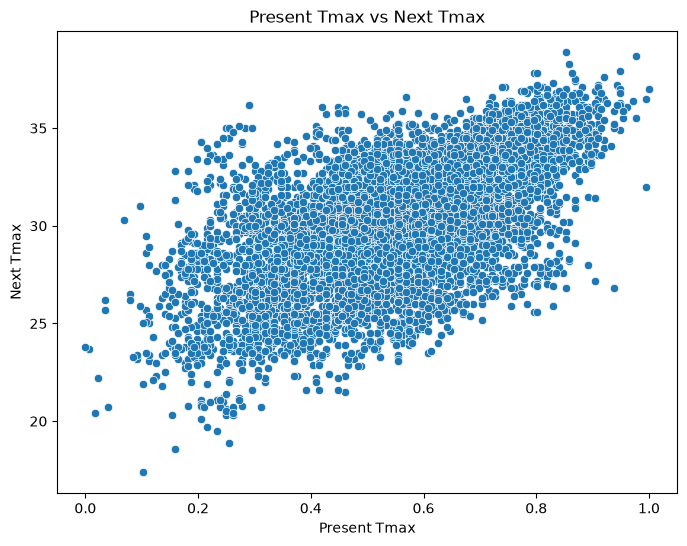

In [86]:
## Scatter Plot 1

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=data['Present_Tmax'],
    y=data['Next_Tmax']
)

plt.xlabel('Present Tmax')
plt.ylabel('Next Tmax')
plt.title('Present Tmax vs Next Tmax')

plt.show()

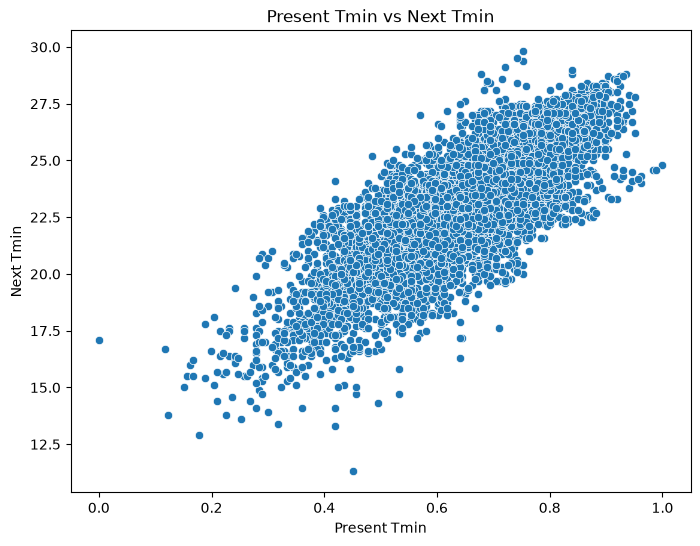

In [87]:
## Scatter Plot 2

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=data['Present_Tmin'],
    y=data['Next_Tmin']
)

plt.xlabel('Present Tmin')
plt.ylabel('Next Tmin')
plt.title('Present Tmin vs Next Tmin')

plt.show()

## Step 7: Designate all features, excluding the two last columns ("Next_Tmax" and "Next_Tmin"), as X_variables.

In [88]:
X_variables = data.drop(columns=['Next_Tmax', 'Next_Tmin'])

In [89]:
X_variables.head()

,Present_Tmax,Present_Tmin,LDAPS_RHmin,LDAPS_RHmax,LDAPS_Tmax_lapse,LDAPS_Tmin_lapse,LDAPS_WS,LDAPS_LH,LDAPS_CC1,LDAPS_CC2,...,station_23.0,station_24.0,station_25.0,station_3.0,station_4.0,station_5.0,station_6.0,station_7.0,station_8.0,station_9.0
0,0.494318,0.543011,0.488518,0.783659,0.499546,0.569132,0.207447,0.365853,0.241862,0.210559,...,0,0,0,0,0,0,0,0,0,0
1,0.676136,0.553763,0.412406,0.771200,0.584480,0.636121,0.148053,0.288703,0.233137,0.260000,...,0,0,0,0,0,0,0,0,0,0
2,0.659091,0.645161,0.367024,0.609716,0.595982,0.670697,0.171575,0.150545,0.216426,0.265884,...,0,0,0,1,0,0,0,0,0,0
3,0.681818,0.650538,0.488316,0.914366,0.577497,0.589934,0.145848,0.349446,0.223692,0.233388,...,0,0,0,0,1,0,0,0,0,0
4,0.647727,0.569892,0.462078,0.760251,0.549257,0.600379,0.150325,0.535505,0.156529,0.258165,...,0,0,0,0,0,1,0,0,0,0


In [90]:
print("Shape of X_variables:", X_variables.shape)

Shape of X_variables: (7723, 49)


## Step 8: Add a column name "Next_Taverage". The values in this column is the average value of column "Next_Tmin" and "Next_Tmax".  Assign the "Next_Taverage" column as Y_variable. 

In [91]:
data['Next_Taverage'] = data[['Next_Tmax', 'Next_Tmin']].mean(axis=1)

Y_variable = data['Next_Taverage']

In [92]:
data['Next_Taverage'].head()

0    25.15
1    26.50
2    27.50
3    28.00
4    26.85
Name: Next_Taverage, dtype: float64

In [93]:
Y_variable.shape

(7723,)

## Step 9: Remove correlated variables. Explain which variables should be removed and why.

In [94]:
# Correlation matrix for X variables only
corr_matrix = X_variables.corr().abs()

# Take only the upper triangle
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Display highly correlated pairs
high_corr_pairs = []

for column in upper_triangle.columns:
    for row in upper_triangle.index:
        if upper_triangle.loc[row, column] > 0.80:
            high_corr_pairs.append(
                (row, column, upper_triangle.loc[row, column])
            )

high_corr_pairs

[('Solar radiation', 'Month', np.float64(0.8418283845380224))]

In [95]:
data[['Solar radiation', 'Month', 'Next_Taverage']].corr()['Next_Taverage']

Solar radiation    0.062673
Month              0.080114
Next_Taverage      1.000000
Name: Next_Taverage, dtype: float64

In [96]:
X_variables = X_variables.drop(columns=['Solar radiation'])

In [97]:
X_variables.columns

Index(['Present_Tmax', 'Present_Tmin', 'LDAPS_RHmin', 'LDAPS_RHmax',
       'LDAPS_Tmax_lapse', 'LDAPS_Tmin_lapse', 'LDAPS_WS', 'LDAPS_LH',
       'LDAPS_CC1', 'LDAPS_CC2', 'LDAPS_CC3', 'LDAPS_CC4', 'LDAPS_PPT1',
       'LDAPS_PPT2', 'LDAPS_PPT3', 'LDAPS_PPT4', 'lat', 'lon', 'DEM', 'Slope',
       'Year', 'Month', 'Day', 'station_1.0', 'station_10.0', 'station_11.0',
       'station_12.0', 'station_13.0', 'station_14.0', 'station_15.0',
       'station_16.0', 'station_17.0', 'station_18.0', 'station_19.0',
       'station_2.0', 'station_20.0', 'station_21.0', 'station_22.0',
       'station_23.0', 'station_24.0', 'station_25.0', 'station_3.0',
       'station_4.0', 'station_5.0', 'station_6.0', 'station_7.0',
       'station_8.0', 'station_9.0'],
      dtype='str')

#### An absolute correlation threshold of 0.80 was used to identify highly correlated predictor variables. Solar radiation and Month had a strong negative correlation of \(r=-0.842\), indicating that they may contain overlapping seasonal information. Their correlations with the target variable Next_Taverage were 0.0627 and 0.0801, respectively. Since Month had the slightly stronger relationship with the target, Month was retained and Solar radiation was removed from the predictor set to reduce redundancy and potential multicollinearity.